# Workshop 4 — Exploración de embeddings RoBERTa
Análisis visual del espacio de representación **antes** del AE/VAE.

In [1]:
import sys
print(sys.executable)

c:\Users\Andro\Documents\UD\2026-3\Machine_Learning\ML-NLP-Sentimental-Analysis-W4\.venv\Scripts\python.exe


In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
import joblib
from pathlib import Path

##  Cargar embeddings y splits

In [4]:
emb = np.load("../data/gold/embeddings_bert.npy")
labels = np.load("../data/gold/labels.npy")
splits = json.loads(Path("../data/gold/splits.json").read_text())

X_train = emb[splits["train"]]
y_train = labels[splits["train"]]
X_val   = emb[splits["validation"]]
y_val   = labels[splits["validation"]]
X_test  = emb[splits["test"]]
y_test  = labels[splits["test"]]

print(f"Train : {X_train.shape}")
print(f"Val   : {X_val.shape}")
print(f"Test  : {X_test.shape}")

Train : (29842, 768)
Val   : (6395, 768)
Test  : (6395, 768)


##  Normalización (StandardScaler — fit solo en train)

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

Path("checkpoints").mkdir(exist_ok=True)
joblib.dump(scaler, "checkpoints/scaler.pkl")
print("Scaler guardado en checkpoints/scaler.pkl")

Scaler guardado en checkpoints/scaler.pkl


## t-SNE sobre embeddings RoBERTa (baseline visual)

Corriendo t-SNE...


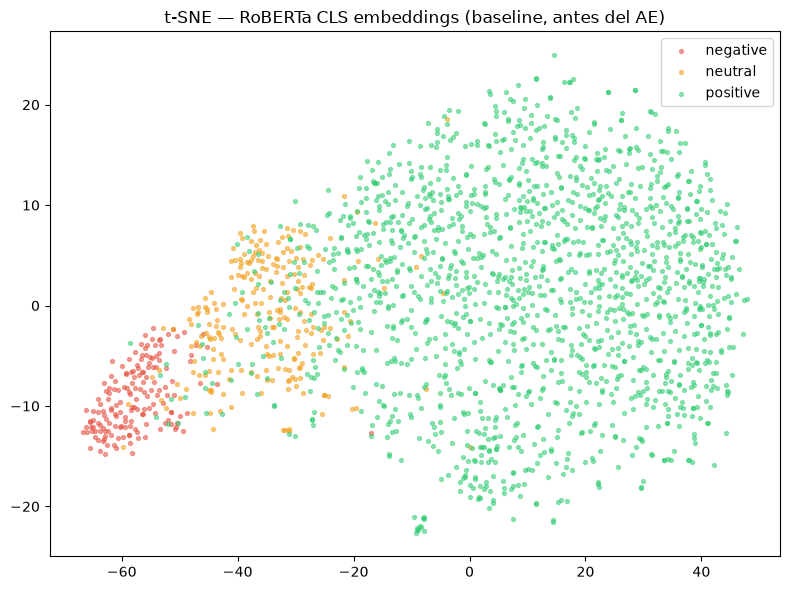

In [ ]:
# Muestra de 2000 puntos para que sea manejable
rng = np.random.default_rng(42)
idx = rng.choice(len(X_train_scaled), size=2000, replace=False)

print("Corriendo t-SNE...")
proj = TSNE(
    n_components=2,
    perplexity=30,
    max_iter=1000,
    random_state=42
).fit_transform(X_train_scaled[idx])

colors = ["#e74c3c", "#f39c12", "#2ecc71"]
fig, ax = plt.subplots(figsize=(8, 6))
for i, name in enumerate(label_names):
    mask = y_train[idx] == i
    ax.scatter(proj[mask, 0], proj[mask, 1],
               c=colors[i], label=name, alpha=0.5, s=8)
ax.legend()
ax.set_title("t-SNE — RoBERTa CLS embeddings (baseline, antes del AE)")
plt.tight_layout()
os.makedirs("images", exist_ok=True)


plt.savefig("images/tsne_roberta_baseline.png", dpi=150)
plt.show()

## Silhouette Score baseline

In [12]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_train_scaled[idx], y_train[idx], random_state=42)
print(f"Silhouette Score (RoBERTa baseline): {score:.4f}")
# Este valor es el baseline para comparar con AE y VAE latent spaces

Silhouette Score (RoBERTa baseline): 0.2572


### Observations

The RoBERTa embedding space shows a **Silhouette Score of 0.2572**, indicating moderate
but limited class separation before any unsupervised compression.

The t-SNE projection reveals two structural issues:
- **Class imbalance**: positive reviews dominate the training set, forming a large
  central mass that crowds out negative and neutral clusters.
- **Neutral–negative overlap**: neutral (yellow) and negative (red) reviews share
  overlapping regions, consistent with their similar low ratings and ambiguous language.
  Positive reviews (green) partially bleed into the neutral region as well.

This baseline will serve as the reference point for comparing the latent spaces
produced by the AE and VAE — a higher Silhouette Score after compression would
indicate that the bottleneck has learned a more structured representation.